In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd

from tensorflow.keras import layers,models
from tensorflow.keras.datasets import mnist

In [14]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 106s 9us/step


In [15]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [16]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Reshape((28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3),
activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,
activation='relu'),
    tf.keras.layers.Dense(10,
activation='softmax') 
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape_2 (Reshape)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1,
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 287s 94ms/step - accuracy: 0.9533 - loss: 0.1557 - val_accuracy: 0.9840 - val_loss: 0.0566
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 164s 82ms/step - accuracy: 0.9839 - loss: 0.0531 - val_accuracy: 0.9867 - val_loss: 0.0489
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 155s 90ms/step - accuracy: 0.9893 - loss: 0.0339 - val_accuracy: 0.9850 - val_loss: 0.0521
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 205s 90ms/step - accuracy: 0.9930 - loss: 0.0219 - val_accuracy: 0.9818 - val_loss: 0.0660
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 236s 109ms/step - accuracy: 0.9951 - loss: 0.0156 - val_accuracy: 0.9877 - val_loss: 0.0547


In [23]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test accuracy:", test_accuracy)

 46/313 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9776 - loss: 0.0646

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9849 - loss: 0.0468
Test accuracy: 0.9848999977111816


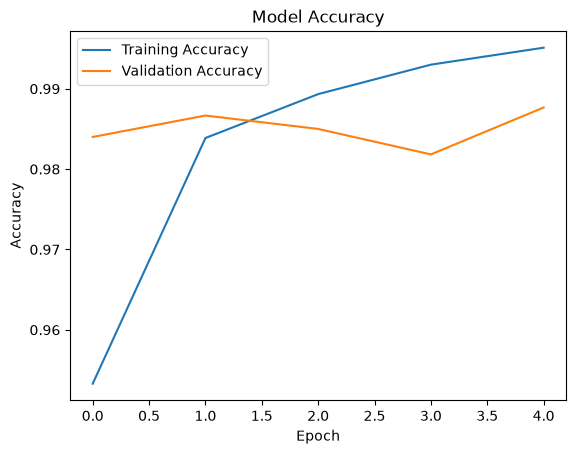

In [24]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

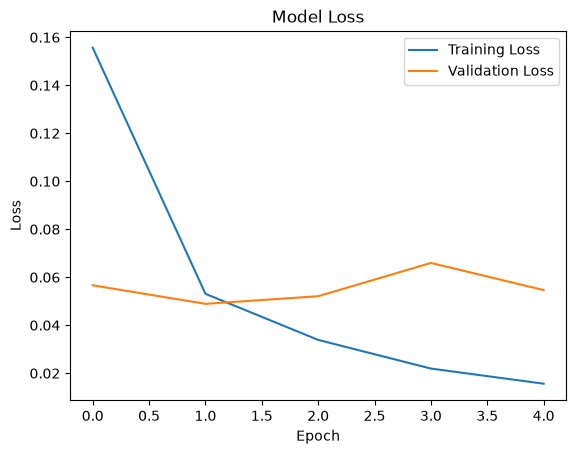

In [25]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [27]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("Test accuracy:", test_accuracy)
print("Test loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - accuracy: 0.9849 - loss: 0.0468
Test accuracy: 0.9848999977111816
Test loss: 0.04677984490990639


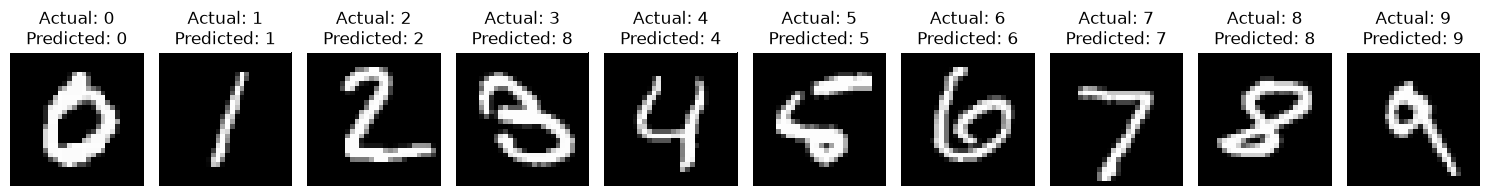

In [34]:
predictions = model.predict(X_test, verbose=0)

plt.figure(figsize=(15, 3))

for digit in range(10):
    index = np.where(y_test == digit)[0][0]

    plt.subplot(1, 10, digit + 1)
    plt.imshow(X_test[index], cmap='gray')

    predicted_digit = np.argmax(predictions[index])

    plt.title(f"Actual: {digit}\nPredicted: {predicted_digit}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [35]:
model.save('handwritten_digit_model.keras')

In [36]:
loaded_model = tf.keras.models.load_model(
    'handwritten_digit_model.keras'
)